# Objective 2 Interpretable statistical models versus ensemble machine learning

**Objective.** Develop and compare interpretable statistical models and ensemble learners for predicting misstatement risk from raw accounting items, accrual-based indicators and other financial-reporting characteristics.

**Design.** Same rolling origin as Objective 1 (train ≤ T−2, test T), Bao et al. serial-fraud recoding, test windows 2003–2008 and 2009–2014.

| Feature set | Content |
|---|---|
| `raw` | 28 raw Compustat items (Bao et al., 2020) |
| `ratio` | 14 financial ratios of Dechow et al. (2011) |
| `accrual` | the 5 accrual-based ratios among them (WC accruals, RSST accruals, Δreceivables, Δinventory, soft assets) |
| `all` | raw + ratio (42 inputs) |

Models: logistic regression (interpretable benchmark), random forest, histogram gradient boosting, XGBoost (fixed and time-series-tuned), RUSBoost, and a **size-only baseline** that ranks firms by total assets with no model. Seed sensitivity of the stochastic learners is reported in notebook 01 (three seeds); here each model is run with seed 42. Differences are tested with a paired firm-cluster bootstrap.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from misstatement.config import *
from misstatement import data, metrics, models, plots
plots.style()
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 3)

In [2]:
d = data.load_bao()
FSETS = {'raw': data.RAW28, 'ratio': data.RAT14, 'accrual': data.ACCRUAL_RATIOS, 'all': data.RAW28 + data.RAT14}
YEARS = BAO_TEST_YEARS + LATE_TEST_YEARS
SEEDS = (42, 7, 2024)
cfg_a = [('Size', 'raw', 'recode'), ('LR', 'ratio', 'recode'), ('LR', 'accrual', 'recode'), ('LR', 'raw', 'recode'),
         ('LR', 'all', 'recode'), ('RUSBoost', 'raw', 'recode'), ('RUSBoost', 'all', 'recode'), ('GBM', 'raw', 'recode'),
         ('GBM', 'all', 'recode'), ('XGB', 'raw', 'recode'), ('XGB', 'all', 'recode'), ('XGB-tuned', 'raw', 'recode')]
cfg_b = [('RF', 'raw', 'recode'), ('RF', 'all', 'recode')]
pa = models.cached(CACHE / 'obj2_predictions_a.parquet', models.rolling, d, cfg_a, YEARS, FSETS, seeds=(42,), verbose=False)
pb = models.cached(CACHE / 'obj2_predictions_b.parquet', models.rolling, d, cfg_b, YEARS, FSETS, seeds=(42,), verbose=False)
pred = pd.concat([pa, pb], ignore_index=True)
pred['spec'] = pred.model + ' | ' + pred.fset
pred.groupby('spec').seed.nunique()

spec
GBM | all          1
GBM | raw          1
LR | accrual       1
LR | all           1
LR | ratio         1
LR | raw           1
RF | all           1
RF | raw           1
RUSBoost | all     1
RUSBoost | raw     1
Size | raw         1
XGB | all          1
XGB | raw          1
XGB-tuned | raw    1
Name: seed, dtype: int64

In [3]:
py = metrics.per_year(pred, ['spec', 'seed'])
py.to_csv(TABLES / 'T07_obj2_metrics_by_year_seed.csv', index=False)

def table(years):
    s = metrics.summarise(py, ['spec', 'seed'], years)
    g = s.groupby('spec')
    t = g[['auc', 'ap', 'ndcg1', 'hits1', 'hits5', 'capture1', 'capture5', 'prec1', 'prec5']].mean()
    return t.sort_values('auc', ascending=False)

t1, t2 = table(BAO_TEST_YEARS), table(LATE_TEST_YEARS)
t1.to_csv(TABLES / 'T08_obj2_models_2003_2008.csv'); t2.to_csv(TABLES / 'T09_obj2_models_2009_2014.csv')
print('Test years 2003-2008'); display(t1.round(4))
print('Test years 2009-2014'); display(t2.round(4))

Test years 2003-2008


,auc,ap,ndcg1,hits1,hits5,capture1,capture5,prec1,prec5
spec,,,,,,,,,
GBM | raw,0.724,0.017,0.017,7.0,33.0,0.027,0.126,0.020,0.019
XGB | raw,0.721,0.018,0.022,8.0,36.0,0.031,0.138,0.023,0.021
XGB-tuned | raw,0.719,0.018,0.021,7.0,35.0,0.027,0.134,0.020,0.020
RUSBoost | raw,0.716,0.018,0.022,9.0,33.0,0.035,0.126,0.026,0.019
XGB | all,0.702,0.017,0.019,7.0,31.0,0.027,0.119,0.020,0.018
RUSBoost | all,0.701,0.018,0.022,7.0,35.0,0.027,0.134,0.020,0.020
GBM | all,0.695,0.017,0.021,7.0,30.0,0.027,0.115,0.020,0.017
LR | all,0.693,0.016,0.024,9.0,28.0,0.035,0.107,0.026,0.016
LR | ratio,0.691,0.018,0.029,7.0,28.0,0.027,0.107,0.020,0.016


Test years 2009-2014


,auc,ap,ndcg1,hits1,hits5,capture1,capture5,prec1,prec5
spec,,,,,,,,,
LR | ratio,0.749,0.009,0.017,4.0,12.0,0.036,0.107,0.012,0.007
LR | raw,0.737,0.009,0.015,3.0,13.0,0.027,0.116,0.009,0.008
LR | all,0.737,0.009,0.013,3.0,12.0,0.027,0.107,0.009,0.007
RUSBoost | all,0.731,0.015,0.039,7.0,16.0,0.062,0.143,0.021,0.010
RUSBoost | raw,0.731,0.012,0.026,4.0,18.0,0.036,0.161,0.012,0.011
GBM | all,0.713,0.008,0.014,3.0,14.0,0.027,0.125,0.009,0.009
RF | raw,0.713,0.013,0.027,4.0,14.0,0.036,0.125,0.012,0.009
XGB | all,0.711,0.009,0.021,5.0,12.0,0.045,0.107,0.015,0.007
XGB | raw,0.701,0.009,0.019,5.0,14.0,0.045,0.125,0.015,0.009


## Paired firm-cluster bootstrap: each model against the ratio logit and against firm size

In [4]:
base = pred[pred.seed == 42]
def sel(spec, years):
    return base[(base.spec == spec) & base.fyear.isin(years)].sort_values(['fyear', 'firm'])

rows = []
for spec in sorted(base.spec.unique()):
    for ref in ('LR | ratio', 'Size | raw'):
        if spec == ref:
            continue
        for lab, yrs in (('2003-2008', BAO_TEST_YEARS), ('2009-2014', LATE_TEST_YEARS)):
            r = metrics.cluster_bootstrap(sel(spec, yrs), sel(ref, yrs), B=300, seed=1)
            rows.append(dict(spec=spec, reference=ref, window=lab, **r))
boot = pd.DataFrame(rows)
# Holm adjustment within each reference x window family
def holm(p):
    o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for i, j in enumerate(o):
        run = max(run, min(1, (m - i) * p[j])); adj[j] = run
    return adj
boot['p_holm'] = boot.groupby(['reference', 'window']).p_boot.transform(lambda s: holm(s.values))
boot.to_csv(TABLES / 'T10_obj2_bootstrap_auc_differences.csv', index=False)
boot[boot.window == '2003-2008'].pivot(index='spec', columns='reference', values=['estimate', 'lo', 'hi', 'p_holm']).round(3)

estimate                    lo                    hi                p_holm           
reference       LR | ratio Size | raw LR | ratio Size | raw LR | ratio Size | raw LR | ratio Size | raw
spec                                                                                                   
GBM | all            0.004      0.053     -0.042      0.006      0.054      0.096        1.0      0.140
GBM | raw            0.033      0.082     -0.016      0.046      0.090      0.124        1.0      0.000
LR | accrual        -0.046      0.004     -0.064     -0.061     -0.025      0.073        0.0      0.873
LR | all             0.002      0.051     -0.034      0.007      0.037      0.096        1.0      0.140
LR | ratio             NaN      0.049        NaN     -0.006        NaN      0.106        NaN      0.260
LR | raw            -0.018      0.031     -0.067     -0.021      0.038      0.082        1.0      0.413
RF | all            -0.000      0.049     -0.052      0.001      0.056      0.098        1.0      0.213
RF | raw            -0.001      0.048     -0.052      0.010      0.060      0.100        1.0      0.200
RUSBoost | all       0.010      0.060     -0.042      0.015      0.062      0.107        1.0      0.060
RUSBoost | raw       0.025      0.075     -0.026      0.034      0.087      0.122        1.0      0.000
Size | raw          -0.049        NaN     -0.106        NaN      0.006        NaN        1.0        NaN
XGB | all            0.011      0.061     -0.039      0.015      0.065      0.104        1.0      0.060
XGB | raw            0.030      0.080     -0.024      0.035      0.093      0.126        1.0      0.000
XGB-tuned | raw      0.028      0.077     -0.024      0.037      0.085      0.124        1.0      0.000

## Calibration of predicted probabilities (pooled 2003–2008, seed 42)

In [5]:
cal = []
for spec, g in base[base.fyear.isin(BAO_TEST_YEARS) & (base.model != 'Size')].groupby('spec'):
    cal.append(dict(spec=spec, **metrics.calibration(g.y.values, g.score.values)))
cal = pd.DataFrame(cal).set_index('spec').sort_values('brier')
cal.to_csv(TABLES / 'T11_obj2_calibration.csv'); cal.round(4)

,brier,cal_slope,cal_intercept,exp_obs
spec,,,,
LR | ratio,0.007,0.675,1.335e-01,0.876
LR | accrual,0.007,0.645,7.350e-02,0.930
LR | all,0.007,0.509,-1.694e-01,1.179
LR | raw,0.007,0.512,-1.654e-01,1.175
GBM | all,0.007,0.497,-2.000e-04,1.000
GBM | raw,0.007,0.557,4.330e-02,0.959
XGB-tuned | raw,0.008,0.488,2.480e-02,0.977
XGB | raw,0.008,0.491,-1.150e-02,1.011
XGB | all,0.008,0.436,-1.510e-02,1.014


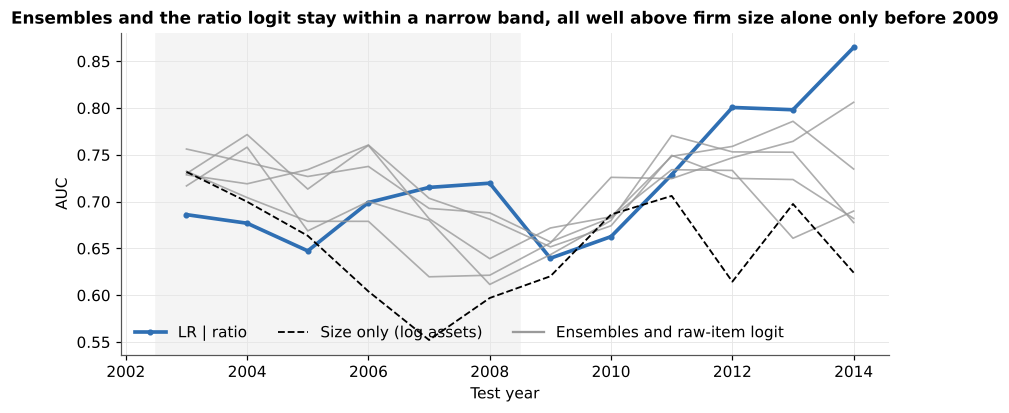

In [6]:
show = ['LR | ratio', 'LR | raw', 'RUSBoost | raw', 'XGB | raw', 'GBM | raw', 'RF | raw', 'Size | raw']
yy = py.groupby(['spec', 'fyear']).auc.mean().reset_index()
fig, ax = plt.subplots(figsize=(9, 3.8))
for s in show:
    q = yy[yy.spec == s]
    if s == 'LR | ratio':
        ax.plot(q.fyear, q.auc, color=plots.ACCENT, lw=2.4, marker='o', ms=3, label=s)
    elif s == 'Size | raw':
        ax.plot(q.fyear, q.auc, color='black', lw=1.2, ls='--', label='Size only (log assets)')
    else:
        ax.plot(q.fyear, q.auc, color=plots.GREY, lw=1.1, alpha=0.8)
ax.plot([], [], color=plots.GREY, label='Ensembles and raw-item logit')
ax.axvspan(2002.5, 2008.5, color='#f4f4f4', zorder=0)
ax.set_ylabel('AUC'); ax.set_xlabel('Test year'); plots.years(ax); ax.legend(loc='lower left', ncol=3)
ax.set_title('Ensembles and the ratio logit stay within a narrow band, all well above firm size alone only before 2009')
plots.save(fig, 'F03_obj2_auc_by_year'); plt.show()

In [7]:
# Feature-set effect for tree models: raw versus raw + ratios
fx = t1.reset_index()
fx[['model', 'fset']] = fx.spec.str.split(' \\| ', expand=True)
fx.pivot_table(index='model', columns='fset', values='auc').round(3)

fset,accrual,all,ratio,raw
model,,,,
GBM,NaN,0.695,NaN,0.724
LR,0.645,0.693,0.691,0.673
RF,NaN,0.691,NaN,0.689
RUSBoost,NaN,0.701,NaN,0.716
Size,NaN,NaN,NaN,0.641
XGB,NaN,0.702,NaN,0.721
XGB-tuned,NaN,NaN,NaN,0.719


## Findings for Objective 2

Read the tables above for exact values; the headline pattern is:

* On 2003–2008 the boosted ensembles on raw items lead the ratio logit by a few hundredths of AUC, but none of the paired firm-cluster bootstrap intervals excludes zero after Holm adjustment: ensembles **match** a transparent logit rather than outperform it.
* Adding the 14 ratios to the raw items does not help the tree models in 2003–2008.
* Ranking by firm size alone already achieves an AUC in the mid-0.6s, so a large part of every model's discrimination reflects the size profile of firms the SEC pursues; the accounting signal adds less than headline AUC values suggest.
* Probability calibration differs sharply: the logit and unweighted XGBoost/GBM are close to calibrated, whereas RUSBoost (undersampling) and the class-weighted random forest grossly overstate probabilities. Their scores should be used only as rankings, or recalibrated.